# Example 5.3: Transmission Angle Constraint
**Chapter 5 · Formulation of the Synthesis Problem**

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/)

## Statement
For the mechanism with **a=50, b=100, c=75, d=90 mm**, calculate the effective transmission angle μ_eff(θ₂) for θ₂ ∈ [0°, 360°] (361 positions). Determine:

- μ_min, μ_max, and μ_avg
- Number of critical positions where μ_eff < 40°

Plot μ_eff(θ₂) highlighting the critical zone and identify the range of θ₂ with the highest risk of losing force transmission.

**Objective:** implement the transmission angle constraint E_TA(x) to be incorporated as a penalty in the GA objective function.

In [1]:
from numpy import *
import matplotlib.pyplot as plt
plt.rcParams.update({'font.family': 'serif', 'font.size': 12})

# ── Effective transmission angle─────────────────────────────────────────
def angulo_transmision(a, b, c, d, th2_arr):
    th2 = radians(th2_arr)
    K1=d/a; K2=d/c; K3=(a**2-b**2+c**2+d**2)/(2*a*c)
    A=cos(th2)-K1-K2*cos(th2)+K3; B=-2*sin(th2)
    C=K1-(K2+1)*cos(th2)+K3; disc=B**2-4*A*C
    th4=where(disc>=0, 2*arctan2(-B-sqrt(maximum(disc,0)),2*A), nan)
    K4=d/b; K5=(c**2-d**2-a**2-b**2)/(2*a*b)
    A2=cos(th2)-K1+K4*cos(th2)+K5; B2=-2*sin(th2)
    C2=K1+(K4-1)*cos(th2)+K5; disc2=B2**2-4*A2*C2
    th3=where(disc>=0, 2*arctan2(-B2-sqrt(maximum(disc2,0)),2*A2), nan)
    mu = abs(th4 - th3)
    mu_eff = where(mu > pi/2, pi - mu, mu)
    return degrees(mu_eff)

# ── Evaluation of the mechanism───────────────────────────────────────────────
a, b, c, d = 50., 100., 75., 90.
th2 = linspace(0, 360, 361)
mu_eff = angulo_transmision(a, b, c, d, th2)
valido   = isfinite(mu_eff)
criticos = (mu_eff < 40) & valido

print("Effective transmission angle:")
print(f"  Minimum : {nanmin(mu_eff):.2f}°  at θ₂ = {th2[nanargmin(mu_eff)]:.1f}°")
print(f"  Maximum : {nanmax(mu_eff):.2f}°  at θ₂ = {th2[nanargmax(mu_eff)]:.1f}°")
print(f"  Average : {nanmean(mu_eff):.2f}°")
print(f"Critical positions (μ_eff < 40°): "
      f"{criticos.sum()} / {valido.sum()} "
      f"({100*criticos.sum()/valido.sum():.1f}%)")



Effective transmission angle:
  Minimum : 20.77°  at θ₂ = 0.0°
  Maximum : 89.97°  at θ₂ = 124.0°
  Average : 60.97°
Critical positions (μ_eff < 40°): 90 / 361 (24.9%)


<>:32: SyntaxWarning: invalid escape sequence '\m'
<>:35: SyntaxWarning: invalid escape sequence '\m'
<>:36: SyntaxWarning: invalid escape sequence '\m'
<>:32: SyntaxWarning: invalid escape sequence '\m'
<>:35: SyntaxWarning: invalid escape sequence '\m'
<>:36: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_2539/1418122434.py:32: SyntaxWarning: invalid escape sequence '\m'
  label='Critical Zone ($\mu < 40^\circ$)')
/tmp/ipykernel_2539/1418122434.py:35: SyntaxWarning: invalid escape sequence '\m'
  ax.axhline(40, color='#d62728', ls='--', lw=1.0, label='Limit $\mu_{\mathrm{min}} = 40^\circ$')
/tmp/ipykernel_2539/1418122434.py:36: SyntaxWarning: invalid escape sequence '\m'
  ax.axhline(90, color='#2ca02c', ls=':', lw=1.0, label='Optimal $\mu = 90^\circ$')


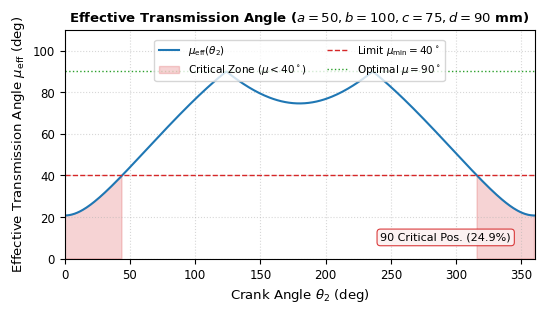

In [3]:
import os
import glob

# ── Automated Filename System ──────────────────────────────────────────
try:
    notebook_files = glob.glob("*.ipynb")
    if notebook_files:
        notebook_name = notebook_files[0].replace('.ipynb', '')
    else:
        notebook_name = "ex5_3_transmission_angle_constraint"
except Exception:
    notebook_name = "ex5_3_transmission_angle_constraint"

# ── Springer Visualization Config ───────────────────────────────────────
import matplotlib.pyplot as plt
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['DejaVu Sans', 'Helvetica', 'Arial'],
    'font.size': 8.5,
    'pdf.fonttype': 42,
    'ps.fonttype': 42
})

fig, ax = plt.subplots(figsize=(5.5, 3.2))

# Plot curves
ax.plot(th2[valido], mu_eff[valido], color='#1f77b4', lw=1.5, label=r'$\mu_{\mathrm{eff}}(\theta_2)$')

# Highlight critical zone
ax.fill_between(th2, 0, mu_eff,
                where=criticos, alpha=0.2, color='#d62728',
                label='Critical Zone ($\mu < 40^\circ$)')

# Limit lines
ax.axhline(40, color='#d62728', ls='--', lw=1.0, label='Limit $\mu_{\mathrm{min}} = 40^\circ$')
ax.axhline(90, color='#2ca02c', ls=':', lw=1.0, label='Optimal $\mu = 90^\circ$')

# Titles and Labels (English)
ax.set_xlabel(r'Crank Angle $\theta_2$ (deg)', fontsize=9.5)
ax.set_ylabel(r'Effective Transmission Angle $\mu_{\mathrm{eff}}$ (deg)', fontsize=9.5)
ax.set_title(f'Effective Transmission Angle ($a={a:.0f}, b={b:.0f}, c={c:.0f}, d={d:.0f}$ mm)', fontsize=9.5, fontweight='bold')

# Grid and Limits
ax.grid(True, ls=':', alpha=0.5)
ax.set_xlim(0, 360)
ax.set_ylim(0, 110) # Safe margin at the top for labels

# Elegant legend
ax.legend(loc='upper center', bbox_to_anchor=(0.5, 0.98), ncol=2, frameon=True, fontsize=7.5)

# Academic information box
info_text = f'{criticos.sum()} Critical Pos. ({100*criticos.sum()/valido.sum():.1f}%)'
ax.text(0.95, 0.08, info_text, transform=ax.transAxes, ha='right', fontsize=8,
        bbox=dict(boxstyle='round,pad=0.3', fc='#fcf1f1', ec='#d62728', lw=0.8, alpha=0.9))

plt.tight_layout()

# Double Export System
plt.savefig(f'{notebook_name}.pdf', format='pdf', bbox_inches='tight')
plt.savefig(f'{notebook_name}.png', format='png', dpi=600, bbox_inches='tight')
plt.show()